# Deep Learning-Based Recommendation Models

Pada sistem rekomendasi modern yang mengandalkan umpan balik implisit (*clicks*, *views*, *purchases*), model faktorisasi klasik seperti *Matrix Factorization* hanya mampu memetakan interaksi secara linear melalui perkalian titik (*dot product*). Pendekatan linear ini sering kali kurang optimal dalam menangkap pola preferensi pengguna yang kompleks dan berdimensi tinggi. Untuk mengatasi keterbatasan tersebut, arsitektur berbasis jaringan saraf tiruan (*neural network*) hadir sebagai solusi melalui **Neural Collaborative Filtering (NCF)**.


In [1]:
from copy import deepcopy
from pathlib import Path
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset
from tqdm.auto import tqdm
from urllib.request import urlretrieve
from zipfile import ZipFile

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn

sns.set_theme(style='whitegrid')

seed = 42
torch.manual_seed(seed)

device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [2]:
def plotTrainingAndValidationLoss(
  modelData: dict[str, any],
  modelName: str,
):
  # Menentukan nomor epoch berdasarkan jumlah riwayat training loss.
  epochNumbers = range(1, len(modelData['trainLossHistory']) + 1)

  # Membuat figure dan axes untuk visualisasi loss.
  fig, ax = plt.subplots(figsize=(10, 5))

  # Menampilkan perubahan training loss pada setiap epoch.
  sns.lineplot(
    x=epochNumbers,
    y=modelData['trainLossHistory'],
    marker='o',
    label='Training Loss',
    ax=ax,
  )

  # Menampilkan perubahan validation loss pada setiap epoch.
  sns.lineplot(
    x=epochNumbers,
    y=modelData['valLossHistory'],
    marker='o',
    label='Validation Loss',
    ax=ax,
  )

  # Menandai epoch terbaik dengan garis vertikal putus-putus.
  ax.axvline(
    x=modelData['bestEpoch'],
    color='gray',
    linestyle='--',
    label=f'Best Epoch: {modelData['bestEpoch']}',
  )

  # Menandai titik validation loss terendah pada epoch terbaik.
  ax.scatter(
    modelData['bestEpoch'],
    modelData['bestValLoss'],
    color='red',
    s=80,
    zorder=5,
  )

  # Mengatur judul grafik dan label masing-masing sumbu.
  ax.set(
    title=f'{modelName} Training and Validation Loss',
    xlabel='Epoch',
    ylabel='Binary Cross-Entropy Loss',
  )

  # Menampilkan legenda dan menyesuaikan tata letak grafik.
  ax.legend()
  plt.tight_layout()
  plt.show()

def plotConfusionMatrix(
  y: list[float],
  yPred: list[float],
  modelName: str,
):
  # Mengonversi probabilitas prediksi menjadi label biner dengan threshold 0.5.
  yPredBin = [
    int(probability >= 0.5)
    for probability in yPred
  ]

  # Menghitung confusion matrix dari target aktual dan label prediksi.
  matrix = confusion_matrix(
    y,
    yPredBin,
    labels=[0, 1],
  )

  # Membuat figure dan axes untuk visualisasi confusion matrix.
  fig, ax = plt.subplots(figsize=(7, 5))

  # Menampilkan confusion matrix dalam bentuk heatmap.
  sns.heatmap(
    matrix,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive'],
    ax=ax,
  )

  # Mengatur judul grafik dan label sumbu.
  ax.set(
    title=f'{modelName} Test Confusion Matrix',
    xlabel='Predicted Label',
    ylabel='Actual Label',
  )

  # Menyesuaikan tata letak dan menampilkan grafik.
  plt.tight_layout()
  plt.show()
  

In [3]:
# Menentukan direktori utama dan lokasi file dataset MovieLens 100K.
pathMl = Path('../res/data/movielens')
pathZip = pathMl / 'ml-100k.zip'
pathRatings = pathMl / 'ml-100k' / 'u.data'
pathItem = pathMl / 'ml-100k' / 'u.item'

# Membuat direktori penyimpanan jika belum tersedia.
pathMl.mkdir(parents=True, exist_ok=True)

# Mengunduh dataset MovieLens 100K jika file ZIP belum tersedia.
if not pathZip.exists():
  urlretrieve(
    'https://files.grouplens.org/datasets/movielens/ml-100k.zip',
    pathZip,
  )

# Mengekstrak file rating pengguna jika belum tersedia.
if not pathRatings.exists():
  with ZipFile(pathZip) as archive:
    archive.extract('ml-100k/u.data', path=pathMl)

In [4]:
# Membaca dataset rating pengguna dan film dari MovieLens 100K.
df = pd.read_csv(
  pathRatings, 
  sep='\t', 
  header=None,
  usecols=[0, 1, 2],
  names=['userId', 'movieId', 'rating'],
)

# Menghapus rating netral (3) dari dataset.
df = df[df.rating != 3].copy()

# Mengonversi rating menjadi target biner: 0 untuk rating 1–2 dan 1 untuk rating 4–5.
df['target'] = (df.rating >= 4).astype(float)

# Mengonversi ID pengguna dan film menjadi indeks numerik mulai dari 0.
df.userId = df.userId.astype('category').cat.codes
df.movieId = df.movieId.astype('category').cat.codes

# Menghitung jumlah pengguna dan film unik untuk menentukan ukuran tabel embedding.
numUsers = df.userId.nunique()
numItems = df.movieId.nunique()

# Menampilkan informasi struktur, tipe data, dan jumlah nilai non-null pada dataset.
df.info()

<class 'pandas.DataFrame'>
Index: 72855 entries, 2 to 99998
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   userId   72855 non-null  int16  
 1   movieId  72855 non-null  int16  
 2   rating   72855 non-null  int64  
 3   target   72855 non-null  float64
dtypes: float64(1), int16(2), int64(1)
memory usage: 1.9 MB


In [5]:
# Membagi dataset menjadi 80% training dan 20% sementara dengan proporsi target tetap seimbang.
trainData, tempData = train_test_split(
  df,
  test_size=0.2,
  random_state=seed,
  stratify=df.target,
)

# Membagi dataset sementara menjadi 10% validation dan 10% testing dari total dataset.
valData, testData = train_test_split(
  tempData,
  test_size=0.5,
  random_state=seed,
  stratify=tempData.target,
)

# Mengatur ulang indeks setiap dataset agar dimulai dari 0 secara berurutan.
trainData = trainData.reset_index(drop=True)
valData = valData.reset_index(drop=True)
testData = testData.reset_index(drop=True)

# Menampilkan jumlah sampel pada masing-masing dataset.
print(f'Train: {len(trainData)}')
print(f'Validation: {len(valData)}')
print(f'Test: {len(testData)}')

Train: 58284
Validation: 7285
Test: 7286


In [6]:
def createDataLoader(
  df: pd.DataFrame,
  batchSize=256,
  shuffle=False,
):
  """
    Membuat DataLoader dari DataFrame untuk proses training, validation, dan testing.

    Args:
      df (pd.DataFrame): Dataset yang berisi ID pengguna, ID film, dan target.
      batchSize (int, optional): Jumlah sampel dalam setiap batch. Default 256.
      shuffle (bool, optional): Mengacak urutan sampel setiap epoch. Default False.

    Returns:
      DataLoader: DataLoader yang menghasilkan batch pengguna, film, dan target.
  """
  
  # Mengonversi kolom DataFrame menjadi tensor dengan tipe data yang sesuai.
  dataset = TensorDataset(
    torch.tensor(df.userId.to_numpy(), dtype=torch.long),
    torch.tensor(df.movieId.to_numpy(), dtype=torch.long),
    torch.tensor(df.target.to_numpy(), dtype=torch.float32),
  )
  
  # Membuat DataLoader untuk membagi dataset menjadi batch.
  return DataLoader(
    dataset,
    batch_size=batchSize,
    shuffle=shuffle,
  )

# Membuat DataLoader training dengan pengacakan sampel setiap epoch.
trainLoader = createDataLoader(trainData, shuffle=True)

# Membuat DataLoader validation tanpa pengacakan sampel.
valLoader = createDataLoader(valData)

# Membuat DataLoader testing tanpa pengacakan sampel.
testLoader = createDataLoader(testData)

## Neural Collaborative Filtering (NCF) dengan Neural Matrix Factorization (NeuMF)

**Neural Collaborative Filtering (NCF)** adalah pendekatan sistem rekomendasi berbasis *neural network* yang mempelajari pola interaksi antara pengguna (*user*) dan item tanpa membatasi hubungan keduanya pada perkalian titik (*dot product*) seperti *Matrix Factorization* (MF) klasik. Salah satu arsitektur NCF adalah **Neural Matrix Factorization (NeuMF)**, yang menggabungkan **Generalized Matrix Factorization (GMF)** untuk memodelkan interaksi laten secara elemen per elemen dan **Multi-Layer Perceptron (MLP)** untuk mempelajari pola interaksi nonlinier. Hasil kedua komponen digabungkan untuk menghasilkan satu nilai prediksi bagi setiap pasangan pengguna–item.

Pada implementasi `class NeuMF(nn.Module)`, model menerima indeks pengguna dan item, lalu menghasilkan **logit**. Probabilitas diperoleh dengan menerapkan fungsi *sigmoid* pada logit saat inferensi; selama pelatihan, `nn.BCEWithLogitsLoss()` menangani fungsi sigmoid secara internal.

> **Catatan:** Penggunaan **GPU direkomendasikan** untuk mempercepat proses pelatihan NeuMF, khususnya ketika jumlah data, dimensi embedding, atau jumlah eksperimen meningkat. Pelatihan tetap dapat dilakukan menggunakan **CPU**, tetapi biasanya membutuhkan waktu lebih lama. Jika komputer tidak memiliki GPU yang kompatibel, alternatifnya adalah menjalankan notebook melalui **Google Colab** atau **Kaggle Notebooks** dengan akselerator GPU, sesuai ketersediaan dan batas penggunaan masing-masing layanan.

---

## 1. Persamaan Model & Pemetaan Variabel Kode

Model NeuMF menggabungkan hasil GMF dan MLP menggunakan persamaan berikut:

$$
\begin{aligned}
\mathbf{g}_{ui} &= \mathbf{p}_{u}^{G} \odot \mathbf{q}_{i}^{G} \\
\mathbf{m}_{ui}^{(0)} &= [\mathbf{p}_{u}^{M};\mathbf{q}_{i}^{M}] \\
\mathbf{m}_{ui}^{(\ell)} &= \operatorname{Dropout}_{0.2}\!\left(\operatorname{ReLU}\!\left(\mathbf{W}_{\ell}\mathbf{m}_{ui}^{(\ell-1)}+\mathbf{b}_{\ell}\right)\right) \\
\mathbf{c}_{ui} &= [\mathbf{g}_{ui};\mathbf{m}_{ui}^{(L)}] \\
s_{ui} &= \mathbf{h}^{T}\mathbf{c}_{ui}+b \\
\hat{y}_{ui} &= \sigma(s_{ui}) = \frac{1}{1+e^{-s_{ui}}}
\end{aligned}
$$

Pada mode evaluasi (`model.eval()`), *dropout* dinonaktifkan sehingga hasil setiap hidden layer hanya melalui transformasi linear dan ReLU. Metode `forward()` mengembalikan $s_{ui}$ (**logit**), bukan $\hat{y}_{ui}$ (**probabilitas**).

### Notasi Umum: Pengguna, Item, dan Embedding

| Simbol Matematis | Variabel dalam Kode  | Penjelasan                                                          |
| :--------------- | :------------------- | :------------------------------------------------------------------ |
| $u$            | `userIds`          | Indeks pengguna yang akan diprediksi.                               |
| $i$            | `itemIds`          | Indeks item atau film yang akan diprediksi.                         |
| $U$            | `numUsers`         | Jumlah pengguna yang menentukan banyaknya baris embedding pengguna. |
| $I$            | `numItems`         | Jumlah item yang menentukan banyaknya baris embedding item.         |
| $d$            | `embeddingDim`     | Dimensi vektor laten pengguna dan item pada setiap komponen.        |
| $L$            | `len(hiddenUnits)` | Jumlah hidden layer pada jaringan MLP.                              |

### Notasi Generalized Matrix Factorization (GMF)

Komponen GMF memodelkan interaksi menggunakan perkalian elemen per elemen (*element-wise product*):

$$
\mathbf{g}_{ui}=\mathbf{p}_{u}^{G}\odot\mathbf{q}_{i}^{G}
$$

| Simbol Matematis       | Variabel dalam Kode                      | Penjelasan                                                |
| :--------------------- | :--------------------------------------- | :-------------------------------------------------------- |
| $\mathbf{p}_{u}^{G}$ | `gmfUser = self.gmfUserEmbed(userIds)` | Vektor embedding pengguna GMF berukuran $d$.            |
| $\mathbf{q}_{i}^{G}$ | `gmfItem = self.gmfItemEmbed(itemIds)` | Vektor embedding item GMF berukuran $d$.                |
| $\odot$              | `gmfUser * gmfItem`                    | Perkalian elemen pada posisi yang sama dari kedua vektor. |
| $\mathbf{g}_{ui}$    | `gmf`                                  | Representasi interaksi GMF berukuran $d$.               |

### Notasi Multi-Layer Perceptron (MLP)

Komponen MLP menggabungkan embedding pengguna dan item, kemudian memprosesnya melalui beberapa hidden layer:

$$
\mathbf{m}_{ui}^{(0)}=[\mathbf{p}_{u}^{M};\mathbf{q}_{i}^{M}]
$$

$$
\mathbf{m}_{ui}^{(\ell)}=\operatorname{Dropout}_{0.2}\left(\operatorname{ReLU}(\mathbf{W}_{\ell}\mathbf{m}_{ui}^{(\ell-1)}+\mathbf{b}_{\ell})\right)
$$

| Simbol Matematis                 | Variabel dalam Kode                      | Penjelasan                                                                            |
| :------------------------------- | :--------------------------------------- | :------------------------------------------------------------------------------------ |
| $\mathbf{p}_{u}^{M}$           | `mlpUser = self.mlpUserEmbed(userIds)` | Vektor embedding pengguna MLP yang terpisah dari GMF.                                 |
| $\mathbf{q}_{i}^{M}$           | `mlpItem = self.mlpItemEmbed(itemIds)` | Vektor embedding item MLP yang terpisah dari GMF.                                     |
| $[\,;\,]$                      | `torch.cat(..., dim=-1)`               | Operasi konkatenasi dua vektor pada dimensi fitur.                                    |
| $\mathbf{m}_{ui}^{(0)}$        | `mlpCombined`                          | Vektor masukan MLP berukuran $2d$.                                                  |
| $\mathbf{W}_{\ell}$            | `nn.Linear(...).weight`                | Matriks bobot pada hidden layer ke-$\ell$.                                          |
| $\mathbf{b}_{\ell}$            | `nn.Linear(...).bias`                  | Vektor bias pada hidden layer ke-$\ell$.                                            |
| $\operatorname{ReLU}$          | `nn.ReLU()`                            | Fungsi aktivasi nonlinier $\max(0,x)$.                                              |
| $\operatorname{Dropout}_{0.2}$ | `nn.Dropout(p=0.2)`                    | Menonaktifkan sebagian aktivasi secara acak saat training; tidak aktif saat evaluasi. |
| $\mathbf{m}_{ui}^{(L)}$        | `mlp = self.mlpNetwork(mlpCombined)`   | Representasi akhir MLP dengan dimensi `hiddenUnits[-1]`.                            |

### Notasi Neural Matrix Factorization (NeuMF)

Hasil GMF dan MLP digabungkan, kemudian dipetakan menjadi satu logit melalui layer linear:

$$
s_{ui}=\mathbf{h}^{T}[\mathbf{g}_{ui};\mathbf{m}_{ui}^{(L)}]+b
$$

$$
\hat{y}_{ui}=\sigma(s_{ui})
$$

| Simbol Matematis    | Variabel dalam Kode                       | Penjelasan                                                           |
| :------------------ | :---------------------------------------- | :------------------------------------------------------------------- |
| $\mathbf{c}_{ui}$ | `neumf = torch.cat([gmf, mlp], dim=-1)` | Representasi gabungan dengan dimensi $d+\texttt{hiddenUnits[-1]}$. |
| $\mathbf{h}$      | `self.output.weight`                    | Bobot linear yang menggabungkan seluruh fitur GMF dan MLP.           |
| $b$               | `self.output.bias`                      | Bias pada layer output NeuMF.                                        |
| $s_{ui}$          | `logits = self.output(neumf)`           | Skor prediksi mentah sebelum sigmoid.                                |
| $\sigma$          | `torch.sigmoid(logits)`                 | Fungsi yang mengubah logit menjadi probabilitas.                     |
| $\hat{y}_{ui}$    | `probabilities` (saat evaluasi)         | Probabilitas target positif untuk pasangan pengguna–item.           |

Dengan konfigurasi `embeddingDim=16` dan `hiddenUnits=(32, 16, 8)`, GMF menghasilkan **16 fitur**, MLP menghasilkan **8 fitur**, dan layer output menerima **24 fitur** untuk menghasilkan **1 logit**.

---

## 2. Cara Kerja Metode `forward(self, userIds, itemIds)`

Metode `forward()` menghitung interaksi pengguna–item melalui dua jalur paralel, yaitu GMF dan MLP. Seluruh operasi dapat diproses sekaligus untuk satu *batch* tanpa melakukan perulangan Python atas setiap pasangan pengguna–item.

Alur komputasi di dalam `forward(userIds, itemIds)`:

1. **`gmfUser` & `gmfItem`:** Mengambil embedding pengguna dan item dari `self.gmfUserEmbed` serta `self.gmfItemEmbed` dengan dimensi masing-masing $d$.
2. **`gmf`:** Menghitung $\mathbf{p}_{u}^{G}\odot\mathbf{q}_{i}^{G}$ menggunakan `gmfUser * gmfItem` untuk menghasilkan representasi GMF.
3. **`mlpUser` & `mlpItem`:** Mengambil embedding pengguna dan item dari tabel MLP yang parameternya **berbeda** dari embedding GMF.
4. **`mlpCombined`:** Menggabungkan kedua embedding MLP menggunakan `torch.cat([mlpUser, mlpItem], dim=-1)` sehingga dimensinya menjadi $2d$.
5. **`mlp`:** Memproses vektor gabungan melalui `self.mlpNetwork`, yang berisi urutan `nn.Linear`, `nn.ReLU`, dan `nn.Dropout(p=0.2)` pada setiap hidden layer.
6. **`neumf`:** Menggabungkan hasil GMF dan MLP menggunakan `torch.cat([gmf, mlp], dim=-1)` untuk membentuk representasi akhir berukuran $d+\texttt{hiddenUnits[-1]}$.
7. **`logits`:** Menghitung skor menggunakan `self.output(neumf)` dan menghapus dimensi terakhir dengan `squeeze(-1)` agar bentuk output menjadi `(batchSize,)`.

Konfigurasi `(32, 16, 8)` pada `hiddenUnits` berarti MLP memproses dimensi **32 → 32 → 16 → 8**, karena input awalnya merupakan konkatenasi dua embedding berdimensi 16. Penggunaan `nn.Dropout(p=0.2)` membantu regularisasi selama pelatihan, sedangkan `model.eval()` menonaktifkannya ketika validasi dan pengujian.

---

## 3. Proses Pelatihan dengan Adam, Binary Cross-Entropy, dan Early Stopping

Metode `forward()` hanya mendefinisikan proses prediksi. Pelatihan dilakukan melalui fungsi `trainNeuMF(model)` di luar kelas menggunakan **Adam** untuk memperbarui parameter embedding, bobot MLP, dan layer output berdasarkan *Binary Cross-Entropy* (BCE).

### Tujuan Pelatihan (Fungsi *Loss*)

Untuk setiap pasangan pengguna–item, model menghasilkan logit $s_{ui}$ dan target biner $y_{ui}\in\{0,1\}$. Fungsi `nn.BCEWithLogitsLoss()` menghitung:

$$
\ell(s_{ui},y_{ui})=-\left[y_{ui}\log\sigma(s_{ui})+(1-y_{ui})\log(1-\sigma(s_{ui}))\right]
$$

Untuk satu *batch* berisi $B$ sampel, loss rata-ratanya adalah:

$$
\mathcal{L}_{\mathrm{BCE}}=\frac{1}{B}\sum_{(u,i)\in\mathcal{B}}\ell(s_{ui},y_{ui})
$$

* **Target Positif ($y_{ui}=1$):** Pada pemrosesan dataset MovieLens yang digunakan, rating 4–5 dianggap sebagai interaksi yang disukai.
* **Target Negatif ($y_{ui}=0$):** Rating 1–2 dianggap sebagai interaksi yang tidak disukai, sedangkan rating 3 dikeluarkan sebagai nilai netral.
* **`BCEWithLogitsLoss`:** Menggabungkan sigmoid dan BCE secara numerik stabil. Oleh karena itu, `forward()` harus mengembalikan **logit**, bukan probabilitas sigmoid.
* **`weightDecay`:** Parameter `weight_decay` pada `torch.optim.Adam` memberikan regularisasi terhadap bobot selama pembaruan optimizer untuk membantu mengurangi *overfitting*.

### Langkah Pembaruan Parameter (Per Satu Batch)

Setiap batch dari `trainLoader` diproses melalui langkah berikut:

1. **`model.train()`:** Mengaktifkan mode pelatihan sehingga dropout bekerja pada hidden layer MLP.
2. **`userBatch`, `itemBatch`, `targetBatch`:** Memindahkan indeks pengguna, indeks item, dan target ke perangkat komputasi menggunakan `.to(device)`.
3. **`optimizer.zero_grad()`:** Mengosongkan gradien sebelum melakukan pembaruan parameter berikutnya.
4. **`logits` & `loss`:** Menjalankan `model(userBatch, itemBatch)` dan menghitung `criterion(logits, targetBatch)`.
5. **`loss.backward()`:** Menghitung gradien seluruh parameter yang berkontribusi terhadap prediksi melalui *backpropagation*.
6. **`optimizer.step()`:** Memperbarui embedding, bobot linear, dan bias menggunakan algoritma Adam.
7. **`trainLoss`:** Menjumlahkan `loss.item() * batchSize`, lalu membaginya dengan jumlah sampel training untuk memperoleh rata-rata loss tiap epoch.

### Validasi dan Early Stopping

Setelah setiap epoch, model dievaluasi menggunakan `model.eval()` dan `torch.no_grad()` untuk menghitung `valLoss` tanpa pembaruan parameter. Jika `valLoss` lebih rendah daripada `bestValLoss`, bobot model disimpan melalui `deepcopy(model.state_dict())` dan penghitung `patienceCounter` diatur kembali ke nol.

Jika validation loss tidak membaik selama **3 epoch berturut-turut** (`patience=3`), pelatihan dihentikan. Bobot dari epoch dengan validation loss terendah dipulihkan menggunakan `model.load_state_dict(bestModelState)`, sehingga evaluasi akhir dilakukan terhadap checkpoint terbaik, bukan sekadar epoch terakhir.

---

## 4. Contoh Hitungan Sederhana

Misalkan model memprediksi apakah **User 1** menyukai **Movie A**. Untuk mempermudah perhitungan, digunakan dimensi embedding $d=2$ dan satu hidden layer MLP dengan 2 neuron (`hiddenUnits=(2,)`). Contoh ini menggunakan bobot ilustratif dan dilakukan dalam **mode evaluasi**, sehingga dropout tidak aktif.

* **Embedding GMF:**

  * $\mathbf{p}_{u}^{G}=[0.8,\ 0.3]$
  * $\mathbf{q}_{i}^{G}=[0.9,\ 0.4]$
* **Embedding MLP:**

  * $\mathbf{p}_{u}^{M}=[0.2,\ 0.5]$
  * $\mathbf{q}_{i}^{M}=[0.6,\ 0.4]$
* **Parameter hidden layer MLP:**

  $$
  \mathbf{W}_{1}=\begin{bmatrix}0.5&0.2&0.1&0.4\\-0.3&0.6&0.2&0.1\end{bmatrix},\qquad\mathbf{b}_{1}=\begin{bmatrix}0.1\\-0.2\end{bmatrix}
  $$
* **Parameter output NeuMF:** $\mathbf{h}=[0.5,\ -0.4,\ 0.7,\ 0.3]$, $b=-0.1$.

**Langkah Perhitungan:**

   $$
      \begin{aligned}
      \mathbf{m}_{ui}^{(0)} &= [\mathbf{p}_{u}^{M};\mathbf{q}_{i}^{M}] \\
      \mathbf{m}_{ui}^{(\ell)} &= \operatorname{Dropout}_{0.2}\!\left(\operatorname{ReLU}\!\left(\mathbf{W}_{\ell}\mathbf{m}_{ui}^{(\ell-1)}+\mathbf{b}_{\ell}\right)\right) \\
      \mathbf{c}_{ui} &= [\mathbf{g}_{ui};\mathbf{m}_{ui}^{(L)}] \\
      s_{ui} &= \mathbf{h}^{T}\mathbf{c}_{ui}+b \\
      \hat{y}_{ui} &= \sigma(s_{ui}) = \frac{1}{1+e^{-s_{ui}}}
      \end{aligned}
   $$

1. **`gmf` (Interaksi GMF):**

   $$
   \mathbf{g}_{ui}=[0.8\times0.9,\ 0.3\times0.4]=[0.72,\ 0.12]
   $$
2. **`mlpCombined` (Input MLP):**

   $$
   \mathbf{m}_{ui}^{(0)}=[0.2,\ 0.5,\ 0.6,\ 0.4]
   $$
3. **`mlp` (Hidden Layer):**

   $$
   \mathbf{W}_{1}\mathbf{m}_{ui}^{(0)}+\mathbf{b}_{1}=[0.52,\ 0.20]
   $$

   $$
   \mathbf{m}_{ui}^{(1)}=\operatorname{ReLU}([0.52,\ 0.20])=[0.52,\ 0.20]
   $$
4. **`neumf` (Konkatenasi GMF dan MLP):**

   $$
   \mathbf{c}_{ui}=[0.72,\ 0.12,\ 0.52,\ 0.20]
   $$
5. **`logits` (Skor Mentah):**

   $$
   s_{ui}=(0.5\times0.72)+(-0.4\times0.12)+(0.7\times0.52)+(0.3\times0.20)-0.1=0.636
   $$
6. **`sigmoid` (Probabilitas Prediksi):**

   $$
   \hat{y}_{ui}=\sigma(0.636)=\frac{1}{1+e^{-0.636}}\approx\mathbf{0.6538}
   $$

Dengan ambang klasifikasi **0.5**, probabilitas $0.6538$ menghasilkan label prediksi **1 (positif)**. Nilai ini merupakan contoh ilustratif, bukan hasil pelatihan model MovieLens yang sebenarnya.

---

## 5. Aplikasi Neural Collaborative Filtering (NeuMF)

NeuMF dapat digunakan pada berbagai sistem rekomendasi yang merepresentasikan interaksi melalui pasangan identitas pengguna dan item:

1. **Rekomendasi Film:** Memperkirakan kemungkinan pengguna menyukai suatu film berdasarkan histori rating pengguna–film. Pada konfigurasi MovieLens ini, model membedakan rating **1–2 (negatif)** dan **4–5 (positif)**.
2. **Rekomendasi Produk E-Commerce:** Mempelajari kecenderungan interaksi pengguna–produk berdasarkan label biner, seperti pembelian atau tindakan tertentu, setelah definisi target dan proses sampling disesuaikan.
3. **Rekomendasi Konten Digital:** Memperkirakan ketertarikan pengguna terhadap video, musik, atau artikel dengan mempelajari pola interaksi sebelumnya.
4. **Pemeringkatan Kandidat Item:** Menghitung skor probabilitas untuk beberapa item yang sudah memiliki embedding terlatih, kemudian mengurutkannya sebagai kandidat rekomendasi bagi pengguna tertentu.

Pada implementasi ini, `forward()` hanya menerima **ID pengguna dan ID item**. Informasi tambahan seperti judul, genre, atau deskripsi film **tidak digunakan secara langsung**, sehingga model belum menangani pengguna atau item baru (*cold-start*) tanpa perubahan arsitektur atau strategi tambahan.

---

## 6. Kelebihan dan Kekurangan Neural Collaborative Filtering (NeuMF)

| Kelebihan (*Pros*)                                                                                                                                                             | Kekurangan (*Cons*)                                                                                                                                                                                             |
| :------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- | :---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| **Memodelkan Pola Nonlinier:** MLP mempelajari hubungan pengguna–item yang lebih fleksibel dibanding pembatasan pada perkalian titik MF klasik.                           | **Rentan Overfitting:** Tabel embedding terpisah dan jaringan MLP memiliki banyak parameter, terutama pada dataset interaksi yang relatif kecil.                                                            |
| **Menggabungkan Dua Pendekatan:** GMF menangkap interaksi laten elemen per elemen, sedangkan MLP membentuk representasi interaksi yang lebih kompleks.                     | **Membutuhkan Tuning Hiperparameter:** Dimensi embedding, ukuran hidden layer, dropout, weight decay, dan early stopping memengaruhi generalisasi.                                                          |
| **Mendukung Pelatihan Berbasis Batch:** Operasi embedding dan neural network dapat dihitung secara paralel melalui PyTorch dan diakselerasi menggunakan GPU.               | **Masalah Cold-Start:** Pengguna atau item yang tidak pernah muncul saat pelatihan tidak memiliki representasi embedding yang telah dipelajari.                                                             |
| **Fleksibel untuk Prediksi Biner:** Output logit dapat dilatih dengan `BCEWithLogitsLoss` dan diubah menjadi probabilitas untuk klasifikasi atau pemeringkatan kandidat. | **Terbatas pada Informasi ID:** Kelas ini belum memanfaatkan fitur konten seperti genre, teks, atau metadata; selain itu, prediksi rating positif tidak otomatis setara dengan prediksi interaksi implisit. |

In [7]:
class NeuMF(nn.Module):
  """
    Implementasi model Neural Matrix Factorization (NeuMF) dengan kombinasi Generalized Matrix Factorization (GMF) dan Multi-Layer Perceptron (MLP).

    Persamaan Model:
    y_hat_ui = sigmoid(h^T * [p_u^G ⊙ q_i^G ; MLP([p_u^M ; q_i^M])] + b)
  """
  
  def __init__(
    self,
    numUsers: int,
    numItems: int,
    embeddingDim=16,
    hiddenUnits=(32, 16, 8),
  ):
    """
      Inisialisasi hiperparameter dan komponen model Neural Matrix Factorization (NeuMF).

      Args:
        numUsers (int): Merepresentasikan jumlah total pengguna, yaitu jumlah baris pada tabel embedding pengguna.
        numItems (int): Merepresentasikan jumlah total item, yaitu jumlah baris pada tabel embedding item.
        embeddingDim (int, optional): Merepresentasikan simbol d, yaitu panjang dimensi vektor embedding untuk setiap pengguna dan item. Default 16.
        hiddenUnits (tuple[int, ...], optional): Merepresentasikan jumlah neuron pada setiap hidden layer MLP secara berurutan. Setiap elemen menentukan jumlah output fitur dari layer tersebut. Default (32, 16, 8).
    """
    
    super().__init__()
    
    # Inisialisasi tabel embedding pengguna dan item untuk komponen GMF.
    # Setiap pengguna dan item direpresentasikan oleh vektor laten berdimensi embeddingDim.
    self.gmfUserEmbed = nn.Embedding(numUsers, embeddingDim)
    self.gmfItemEmbed = nn.Embedding(numItems, embeddingDim)
    
    # Inisialisasi tabel embedding pengguna dan item untuk komponen MLP.
    # Embedding GMF dan MLP menggunakan parameter yang terpisah.
    self.mlpUserEmbed = nn.Embedding(numUsers, embeddingDim)
    self.mlpItemEmbed = nn.Embedding(numItems, embeddingDim)
    
    # Menyiapkan daftar layer yang akan disusun menjadi jaringan MLP.
    mlpLayers: list[nn.Module] = []
    
    # Menentukan jumlah fitur input layer pertama MLP.
    # Input berasal dari konkatenasi embedding pengguna dan item.
    inFeatures = embeddingDim * 2
    
    # Membangun hidden layer MLP berdasarkan jumlah neuron yang ditentukan.
    for unit in hiddenUnits:
      # Menambahkan layer linear untuk transformasi fitur.
      # nn.Linear mengubah jumlah fitur dari inFeatures menjadi unit.
      # ReLU digunakan sebagai fungsi aktivasi setelah transformasi linear.
      mlpLayers += [
        nn.Linear(inFeatures, unit),
        nn.ReLU(),
        nn.Dropout(p=0.2),
      ]
      
      # Memperbarui jumlah fitur input untuk layer berikutnya.
      # Output layer saat ini menjadi input layer selanjutnya.
      inFeatures = unit
    
    # Menggabungkan seluruh layer menjadi satu jaringan MLP berurutan.
    self.mlpNetwork = nn.Sequential(*mlpLayers)
    
    # Inisialisasi layer output NeuMF.
    # Jumlah input merupakan gabungan dimensi output GMF dan MLP.
    # GMF menghasilkan embeddingDim fitur, sedangkan MLP menghasilkan hiddenUnits[-1] fitur.
    # Layer menghasilkan satu nilai logit untuk setiap pasangan pengguna dan item.
    self.output = nn.Linear(embeddingDim + hiddenUnits[-1], 1)
    
    # Menginisialisasi bobot embedding dengan distribusi normal.
    self._initializeWeights()
    
  def _initializeWeights(self):
    """
      Inisialisasi bobot embedding pengguna dan item pada komponen GMF dan MLP menggunakan distribusi normal.

      Setiap bobot diinisialisasi dengan nilai rata-rata 0 dan standar deviasi 0.01 untuk memberikan nilai awal acak dengan magnitudo kecil sebelum proses training.
    """
    
    # Inisialisasi bobot embedding pengguna dan item pada komponen GMF.
    # Setiap bobot diambil dari distribusi normal dengan rata-rata 0 dan standar deviasi 0.01.
    nn.init.normal_(self.gmfUserEmbed.weight, std=0.01)
    nn.init.normal_(self.gmfItemEmbed.weight, std=0.01)
    
    # Inisialisasi bobot embedding pengguna dan item pada komponen MLP.
    # Setiap bobot diambil dari distribusi normal dengan rata-rata 0 dan standar deviasi 0.01.
    nn.init.normal_(self.mlpUserEmbed.weight, std=0.01)
    nn.init.normal_(self.mlpItemEmbed.weight, std=0.01)
    
  def forward(
    self,
    userIds: torch.Tensor,
    itemIds: torch.Tensor,
  ) -> torch.Tensor:
    """
      Melakukan proses forward pass model Neural Matrix Factorization (NeuMF) untuk menghasilkan prediksi interaksi antara pengguna dan item.

      Args:
        userIds (torch.Tensor): Merepresentasikan 1D pengguna yang digunakan untuk mengambil vektor embedding dari tabel embedding GMF dan MLP.
        itemIds (torch.Tensor): Merepresentasikan 1D item yang digunakan untuk mengambil vektor embedding dari tabel embedding GMF dan MLP.

      Returns:
        torch.Tensor: Menghasilkan nilai logit untuk setiap pasangan pengguna dan item. Nilai logit merupakan hasil kombinasi komponen GMF dan MLP sebelum diterapkan fungsi aktivasi sigmoid.
    """
    
    # Mengambil vektor embedding pengguna dan item dari komponen GMF.
    gmfUser = self.gmfUserEmbed(userIds)
    gmfItem = self.gmfItemEmbed(itemIds)
    
    # Menghitung interaksi antara embedding pengguna dan item menggunakan perkalian elemen per elemen.
    # Hasilnya merupakan representasi interaksi pengguna dan item pada komponen GMF.
    gmf = gmfUser * gmfItem
    
    # Mengambil vektor embedding pengguna dan item dari komponen MLP.
    mlpUser = self.mlpUserEmbed(userIds)
    mlpItem = self.mlpItemEmbed(itemIds)
    
    # Menggabungkan embedding pengguna dan item pada dimensi fitur sebagai input jaringan MLP.
    mlpCombined = torch.cat(
      [mlpUser, mlpItem],
      dim=-1,
    )
    
    # Memproses hasil konkatenasi embedding melalui jaringan MLP.
    mlp = self.mlpNetwork(mlpCombined)
    
    # Menggabungkan representasi interaksi dari GMF dan MLP pada dimensi fitur.
    neumf = torch.cat(
      [gmf, mlp],
      dim=-1,
    )
    
    # Menghitung nilai logit menggunakan layer output NeuMF.
    # Nilai logit merupakan hasil transformasi linear dari representasi gabungan GMF dan MLP.
    logits = self.output(neumf)
    
    # Menghilangkan dimensi terakhir yang berukuran 1 agar output berbentuk satu nilai logit per pasangan pengguna dan item.
    return logits.squeeze(-1)

In [8]:
def trainNeuMF(
  model: NeuMF,
  epochs=20, 
  lr=1e-3,
  patience=3,
  weightDecay=1e-5,
):
  """
    Melatih model NeuMF dengan optimasi Adam, validasi, dan early stopping.

    Args:
      model (NeuMF): Model NeuMF yang akan dilatih.
      epochs (int, optional): Jumlah maksimum epoch pelatihan. Default 20.
      lr (float, optional): Learning rate optimizer Adam. Default 1e-3.
      patience (int, optional): Jumlah epoch tanpa perbaikan sebelum early stopping. Default 3.
      weightDecay (float, optional): Koefisien regularisasi weight decay. Default 1e-5.

    Returns:
      dict[str, Any]:
        Epoch terbaik, validation loss terbaik, riwayat training loss
        dan riwayat validation loss.
  """
  
  # Menggunakan Binary Cross-Entropy Loss untuk klasifikasi biner berbasis logit.
  criterion = nn.BCEWithLogitsLoss()
  
  # Menginisialisasi optimizer Adam dengan regularisasi weight decay.
  optimizer = torch.optim.Adam(
    model.parameters(), 
    lr=lr,
    weight_decay=weightDecay,
  )

  # Menyiapkan variabel untuk menyimpan model terbaik dan memantau early stopping.
  bestEpoch = 0
  bestModelState = None
  bestValLoss = float('inf')
  patienceCounter = 0

  # Membuat progress bar untuk memantau proses pelatihan setiap epoch.
  progressBar = tqdm(
    range(epochs),
    desc='Training',
    unit='epoch',
  )

  # Menyimpan riwayat loss untuk visualisasi dan evaluasi.
  trainLossHistory = []
  valLossHistory = []
  
  for epoch in range(epochs):
    # Mengaktifkan mode training dan menginisialisasi akumulasi training loss.
    model.train()
    trainLoss = 0.0
    
    for batch in trainLoader:
      # Memindahkan seluruh tensor batch ke perangkat komputasi.
      userBatch, itemBatch, targetBatch = (
        tensor.to(device, non_blocking=True)
        for tensor in batch
      )
      
      # Mengosongkan gradien dari iterasi sebelumnya.
      optimizer.zero_grad()
      
      # Menghitung prediksi logit dan training loss.
      logits = model(userBatch, itemBatch)
      loss = criterion(logits, targetBatch)
      
      # Menghitung gradien dan memperbarui parameter model.
      loss.backward()
      optimizer.step()
      
      # Mengakumulasi loss berdasarkan jumlah sampel dalam batch.
      trainLoss += loss.item() * userBatch.size(0)
    
    # Menghitung rata-rata training loss dan menyimpan riwayatnya.
    trainLoss /= len(trainLoader.dataset)
    trainLossHistory.append(trainLoss)   
    
    # Mengaktifkan mode evaluasi dan menginisialisasi validation loss.
    model.eval()
    valLoss = 0.0
    
    # Melakukan validasi tanpa menghitung gradien.
    with torch.no_grad():
      for batch in valLoader:
        # Memindahkan seluruh tensor batch ke perangkat komputasi.
        userBatch, itemBatch, targetBatch = (
          tensor.to(device, non_blocking=True)
          for tensor in batch
        )
        
        # Menghitung prediksi logit dan validation loss.
        logits = model(userBatch, itemBatch)
        loss = criterion(logits, targetBatch)
        
        # Mengakumulasi loss berdasarkan jumlah sampel dalam batch.
        valLoss += loss.item() * userBatch.size(0)
    
    # Menghitung rata-rata validation loss dan menyimpan riwayatnya.
    valLoss /= len(valLoader.dataset)
    valLossHistory.append(valLoss)
    
    # Menyimpan parameter model jika validation loss mencapai nilai terbaik.
    if valLoss < bestValLoss:
      bestValLoss = valLoss
      bestEpoch = epoch + 1
      bestModelState = deepcopy(model.state_dict())
      patienceCounter = 0
    else:
      # Menambah penghitung jika validation loss tidak membaik.
      patienceCounter += 1
    
    # Memperbarui informasi loss dan early stopping pada progress bar.
    progressBar.set_postfix(
      bestEpoch=bestEpoch,
      patience=f'{patienceCounter}/{patience}',
      valLoss=f'{valLoss:.4f}',
      valLossBest=f'{bestValLoss:.4f}',
      trainLoss=f'{trainLoss:.4f}',
    )
    
    # Memperbarui jumlah epoch yang telah selesai.
    progressBar.update(1)
    
    # Menghentikan pelatihan jika batas patience tercapai.
    if patienceCounter >= patience:
      tqdm.write(f'Early stopping at epoch {epoch + 1}')
      break
  
  # Menutup progress bar setelah pelatihan selesai.
  progressBar.close()
  
  # Mengembalikan parameter model dari epoch dengan validation loss terbaik.
  if bestModelState is not None:
    model.load_state_dict(bestModelState)
  
  # Mengembalikan informasi dan riwayat loss untuk evaluasi.
  return {
    'bestEpoch': bestEpoch,
    'bestValLoss': bestValLoss,
    'trainLossHistory': trainLossHistory,
    'valLossHistory': valLossHistory,
  }


In [9]:
neuMF = NeuMF(
  numUsers=numUsers,
  numItems=numItems,
  embeddingDim=16,
  hiddenUnits=[32, 16, 8],
).to(device)

# Menjalankan pelatihan dan menyimpan hasil evaluasi model.
neuMFData = trainNeuMF(neuMF)

Training:   0%|          | 0/20 [00:00<?, ?epoch/s]

Early stopping at epoch 8


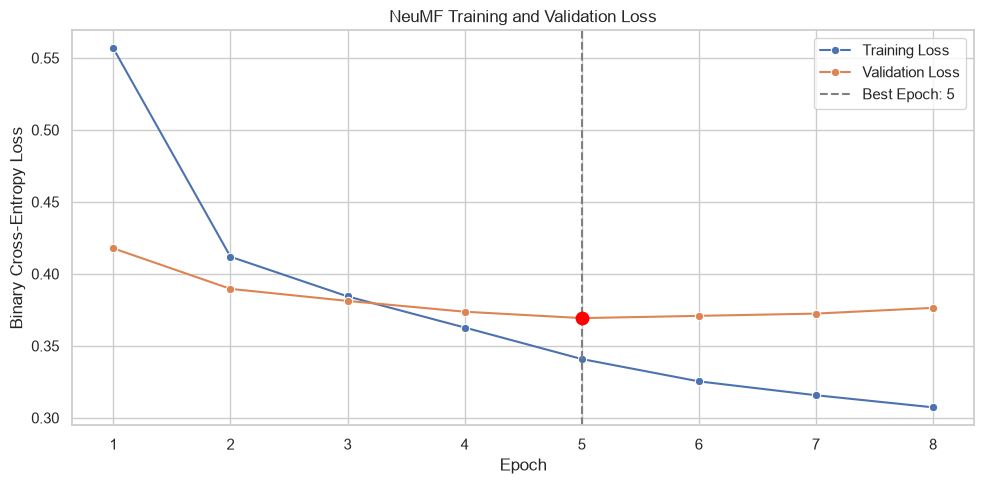

In [10]:
plotTrainingAndValidationLoss(neuMFData, 'NeuMF')

In [11]:
# Mengaktifkan mode evaluasi untuk menonaktifkan dropout.
neuMF.eval()

# Menginisialisasi akumulasi test loss serta penyimpanan hasil prediksi dan target.
testLoss = 0.0
testPredictions = []
testTargets = []

# Menggunakan Binary Cross-Entropy Loss untuk klasifikasi biner berbasis logit.
criterion = nn.BCEWithLogitsLoss()

# Melakukan evaluasi pada dataset testing tanpa menghitung gradien.
with torch.inference_mode():
  for batch in testLoader:
    # Memindahkan seluruh tensor batch ke perangkat komputasi.
    userBatch, itemBatch, targetBatch = (
      tensor.to(device, non_blocking=True)
      for tensor in batch
    )

    # Menghitung prediksi logit dan test loss.
    logits = neuMF(userBatch, itemBatch)
    loss = criterion(logits, targetBatch)

    # Mengakumulasi loss berdasarkan jumlah sampel dalam batch.
    testLoss += loss.item() * userBatch.size(0)

    # Mengonversi logit menjadi probabilitas menggunakan sigmoid.
    probabilities = torch.sigmoid(logits)

    # Menyimpan probabilitas prediksi dan target aktual ke dalam list.
    testPredictions.extend(probabilities.cpu().tolist())
    testTargets.extend(targetBatch.cpu().tolist())
    
# Menghitung rata-rata test loss berdasarkan jumlah seluruh sampel.
testLoss /= len(testLoader.dataset)

# Menampilkan hasil test loss model.
print(f'Test Loss: {testLoss:.4f}')

Test Loss: 0.3702


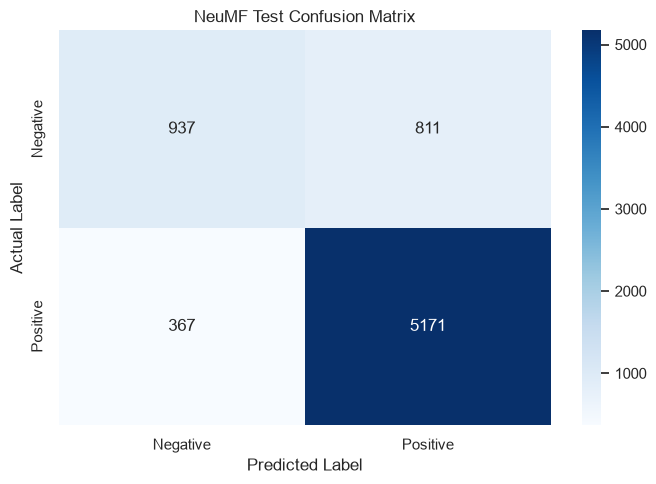

In [12]:
plotConfusionMatrix(testTargets, testPredictions, 'NeuMF')

## Deep Factorization Machine (DeepFM)

**Deep Factorization Machine (DeepFM)** adalah model rekomendasi yang menggabungkan **Factorization Machine (FM)** dan **Deep Neural Network (DNN)**. FM mempelajari kontribusi setiap fitur dan interaksi antar pasangan fitur melalui perkalian titik (*dot product*). DNN mempelajari hubungan nonlinier dari embedding yang sama. Untuk pasangan pengguna–film, kedua komponen menghasilkan skor yang dijumlahkan menjadi satu **logit**.

Pada implementasi `class DeepFM(nn.Module)`, fungsi `encodeDeepFM()` mengubah ID pengguna dan film menjadi **vektor fitur**. Metode `forward()` menerima vektor tersebut dan menghasilkan logit. Fungsi `trainDeepFM()` menggunakan `nn.BCEWithLogitsLoss()` selama pelatihan. Saat inferensi, `torch.sigmoid(logits)` mengubah logit menjadi probabilitas bahwa pengguna memberi rating positif.

> **Catatan:** Penggunaan **GPU direkomendasikan** untuk mempercepat proses pelatihan NeuMF, khususnya ketika jumlah data, dimensi embedding, atau jumlah eksperimen meningkat. Pelatihan tetap dapat dilakukan menggunakan **CPU**, tetapi biasanya membutuhkan waktu lebih lama. Jika komputer tidak memiliki GPU yang kompatibel, alternatifnya adalah menjalankan notebook melalui **Google Colab** atau **Kaggle Notebooks** dengan akselerator GPU, sesuai ketersediaan dan batas penggunaan masing-masing layanan.

---

## 1. Persamaan Model & Pemetaan Variabel Kode

Model DeepFM menggabungkan hasil FM dan DNN menggunakan persamaan berikut.

$$
\begin{aligned}
\mathbf e_j &= x_j\mathbf v_j \\
y_{\mathrm{FM}} &= w_0+\sum_{j=0}^{n-1} [\mathbf w]_j x_j
  +\sum_{0\le j<t<n}\langle\mathbf e_j,\mathbf e_t\rangle \\
\mathbf a^{(0)} &= \operatorname{concat}(\mathbf e_0,\ldots,\mathbf e_{n-1}) \\
\mathbf a^{(\ell)} &= \operatorname{ReLU}\!\left(\mathbf W^{(\ell)}\mathbf a^{(\ell-1)}+\mathbf b^{(\ell)}\right) \\
y_{\mathrm{DNN}} &= \mathbf h^\top\mathbf a^{(L)}+c \\
z_{ui} &= y_{\mathrm{FM}}+y_{\mathrm{DNN}} \\
\hat y_{ui} &= \sigma(z_{ui})=\frac{1}{1+e^{-z_{ui}}}.
\end{aligned}
$$

Indeks kolom fitur dimulai dari 0 agar sesuai dengan pengindeksan PyTorch. Setiap persamaan di atas berlaku untuk satu sampel. Kode menghitung seluruh sampel dalam satu *batch* sekaligus.

### Notasi Umum: Pengguna, Item, dan Embedding

Untuk pengguna $u$ dan film $i$, `encodeDeepFM()` menempatkan fitur pengguna pada kolom $u$ dan fitur film pada kolom $U+i$.

$$
n=U+I,\qquad
x_j=
\begin{cases}
1, & j=u \text{ atau } j=U+i,\\
0, & \text{lainnya}.
\end{cases}
$$

| Simbol Matematis            | Variabel dalam Kode                             | Penjelasan                                                                                                                            |
| :-------------------------- | :---------------------------------------------- | :------------------------------------------------------------------------------------------------------------------------------------ |
| $u,\ i$                   | `userIds`, `itemIds`                        | Indeks pengguna dan film setelah pengodean. Keduanya dimulai dari 0.                                                                  |
| $U,\ I$                   | `numUsers`, `numItems`                      | Jumlah pengguna dan film unik pada data yang telah diproses.                                                                          |
| $n$                       | `self.numFeatures`                            | Jumlah kolom input. Model diinisialisasi dengan `numFeatures=numUsers + numItems`.                                                  |
| $B$                       | `batchSize`, `x.size(0)`                    | Jumlah sampel dalam satu batch.                                                                                                       |
| $j,\ x_j$                 | Indeks kolom, `x[:, j]`                       | Posisi fitur dan nilainya pada setiap sampel.                                                                                         |
| $k$                       | `self.embedDim`                               | Jumlah koordinat laten untuk setiap fitur.                                                                                            |
| $\mathbf V,\ \mathbf v_j$ | `self.embed.weight`, `self.embed.weight[j]` | Matriks embedding berukuran $(n,k)$ dan vektor embedding pada baris $j$.                                                          |
| $\mathbf e_j$             | `e[:, j, :]`                                  | Embedding berbobot $x_j\mathbf v_j$. Fitur aktif menyumbangkan $\mathbf v_j$, sedangkan fitur bernilai 0 menghasilkan vektor nol. |

Misalnya, dengan 3 pengguna dan 2 film, pasangan `userId=1` dan `itemId=0` mengaktifkan kolom 1 dan $3+0=3$. Vektor inputnya adalah $[0,1,0,1,0]$. Film dengan ID 0 tetap memiliki fitur bernilai 1 pada kolomnya.

### Notasi Factorization Machine (FM)

FM menjumlahkan bias global, kontribusi linear, dan interaksi pasangan fitur. Untuk koordinat laten $f$, kode menghitung kuadrat jumlah dan jumlah kuadrat secara terpisah.

$$
\begin{aligned}
S_f &= \left(\sum_{j=0}^{n-1} e_{jf}\right)^2,
& Q_f &= \sum_{j=0}^{n-1} e_{jf}^2,\\
y_{\mathrm{FM}} &=
\underbrace{w_0+\sum_{j=0}^{n-1}[\mathbf w]_j x_j}_{\text{bagian linear}}
+\underbrace{\frac12\sum_{f=1}^{k}(S_f-Q_f)}_{\text{bagian interaksi}}.
\end{aligned}
$$

| Simbol Matematis                 | Variabel dalam Kode | Penjelasan                                                                                                    |
| :------------------------------- | :------------------ | :------------------------------------------------------------------------------------------------------------ |
| $w_0$                          | `self.w0`         | Bias global yang diinisialisasi dengan 0.                                                                     |
| $[\mathbf w]_j$                | `self.w[j]`       | Bobot linear fitur ke-$j$ yang diinisialisasi dengan 0.                                                     |
| $w_0+\sum_j [\mathbf w]_j x_j$ | `linearPart`      | Pada satu pasangan pengguna–film, nilainya adalah $w_0+[\mathbf w]_u+[\mathbf w]_{U+i}$.                   |
| $e_{jf}$                       | Satu elemen `e`   | Koordinat laten ke-$f$ dari embedding berbobot fitur ke-$j$.                                              |
| $S_f$                          | `sumSquare`       | Menjumlahkan embedding pada dimensi fitur, lalu mengkuadratkan hasilnya.                                      |
| $Q_f$                          | `squareSum`       | Mengkuadratkan setiap elemen embedding, lalu menjumlahkannya pada dimensi fitur.                              |
| $\frac12\sum_f(S_f-Q_f)$       | `interactionPart` | Total interaksi pasangan fitur. Faktor $\frac12$ mengoreksi penghitungan setiap pasangan sebanyak dua kali. |
| $y_{\mathrm{FM}}$              | `fm`              | Skor FM yang diperoleh dari `linearPart + interactionPart`.                                                 |

Saat hanya pengguna dan film yang aktif, interaksinya sama dengan $\langle\mathbf v_u,\mathbf v_{U+i}\rangle$. Kode menghitungnya melalui `sumSquare` dan `squareSum` sehingga persamaan yang sama juga berlaku untuk lebih banyak fitur aktif.

### Notasi Deep Neural Network (DNN)

DNN menggabungkan seluruh embedding berbobot sesuai urutan kolom fitur, kemudian memproses vektor gabungan melalui hidden layer.

$$
\mathbf a^{(0)}=\operatorname{concat}(\mathbf e_0,\ldots,\mathbf e_{n-1}),\qquad
\mathbf a^{(\ell)}=\operatorname{ReLU}\!\left(\mathbf W^{(\ell)}\mathbf a^{(\ell-1)}+\mathbf b^{(\ell)}\right).
$$

| Simbol Matematis                            | Variabel dalam Kode                          | Penjelasan                                                                                     |
| :------------------------------------------ | :------------------------------------------- | :--------------------------------------------------------------------------------------------- |
| $\mathbf a^{(0)}$                         | `a0 = e.flatten(start_dim=1)`              | Vektor input DNN berukuran $n k$ per sampel. Posisi fitur yang tidak aktif tetap terisi nol. |
| $\ell,\ L$                                | Posisi hidden layer, `len(hiddenUnits)`    | Nomor hidden layer dan jumlah seluruh hidden layer.                                            |
| $\mathbf W^{(\ell)},\ \mathbf b^{(\ell)}$ | `nn.Linear(inFeatures, unit)`              | Matriks bobot dan vektor bias pada hidden layer ke-$\ell$.                                   |
| $\operatorname{ReLU}$                     | `nn.ReLU()`                                | Fungsi aktivasi $\max(0,t)$ untuk setiap elemen $t$.                                       |
| $\mathbf a^{(L)}$                         | `dnnInput = self.dnn(a0)`                  | Hasil hidden layer terakhir yang menjadi input bagi layer output.                              |
| $\mathbf h,\ c$                           | `self.output.weight`, `self.output.bias` | Bobot dan bias yang mengubah representasi akhir menjadi satu skor.                             |
| $y_{\mathrm{DNN}}$                        | `dnnOutput`                                | Skor DNN yang dihitung dengan `self.output(dnnInput).squeeze(-1)`.                           |

### Notasi Deep Factorization Machine (DeepFM)

$$
z_{ui}=y_{\mathrm{FM}}+y_{\mathrm{DNN}},\qquad \hat y_{ui}=\sigma(z_{ui}).
$$

| Simbol Matematis | Variabel dalam Kode               | Penjelasan                                                                                   |
| :--------------- | :-------------------------------- | :------------------------------------------------------------------------------------------- |
| $z_{ui}$       | `logits = fm + dnnOutput`       | Skor mentah yang dikembalikan oleh `forward()` untuk setiap pasangan pengguna–film.       |
| $\sigma$       | `torch.sigmoid(logits)`         | Fungsi yang mengubah logit menjadi probabilitas saat inferensi.                              |
| $\hat y_{ui}$  | `probabilities` (saat evaluasi) | Probabilitas prediksi untuk target positif, yaitu rating 4–5 pada data yang telah disaring. |

Dengan `embedDim=16` dan `hiddenUnits=(32, 16, 8)`, DNN menerima **$16n$ fitur** per sampel dan menghasilkan **8 fitur** pada hidden layer terakhir. Layer output mengubah 8 fitur tersebut menjadi **1 skor DNN** yang dijumlahkan dengan **1 skor FM**.

---

## 2. Cara Kerja Metode `forward(self, x)`

Sebelum `forward()` dipanggil, `encodeDeepFM()` membuat tensor `float32` berukuran `(batchSize, numUsers + numItems)` pada perangkat yang sama dengan `userIds`. Tensor `rows` memasangkan setiap baris dengan ID pengguna dan film milik sampel tersebut.

Alur komputasi di dalam `forward(x)` mengikuti urutan berikut.

1. **`e`** mengambil seluruh baris `self.embed` dan mengalikannya dengan `x.unsqueeze(-1)`. Hasilnya berukuran `(batchSize, numFeatures, embedDim)` dan digunakan bersama oleh FM dan DNN.
2. **`linearPart`** menghitung `self.w0 + (self.w * x).sum(dim=1)` sehingga setiap sampel memperoleh satu skor linear.
3. **`sumSquare` dan `squareSum`** menghitung dua tensor berukuran `(batchSize, embedDim)`. Operasi `dim=1` pada `e` menjumlahkan fitur dalam satu sampel.
4. **`interactionPart` dan `fm`** menjumlahkan selisih kedua tensor pada dimensi laten, mengalikannya dengan 0.5, lalu menambahkan hasil interaksi ke skor linear.
5. **`a0`** meratakan dimensi fitur dan embedding melalui `e.flatten(start_dim=1)`. Dimensi batch tetap terpisah.
6. **`dnnInput` dan `dnnOutput`** memproses `a0` melalui `self.dnn` dan `self.output`. Operasi `squeeze(-1)` mengubah bentuk `(batchSize, 1)` menjadi `(batchSize,)`.
7. **`logits`** menjumlahkan `fm` dan `dnnOutput` untuk menghasilkan satu logit per sampel.

Konfigurasi `hiddenUnits=(32, 16, 8)` menghasilkan urutan dimensi $nk\rightarrow32\rightarrow16\rightarrow8$ sebelum layer output. Meskipun hanya dua fitur yang aktif, `flatten(start_dim=1)` mempertahankan posisi seluruh $n$ fitur pada input DNN.

---

## 3. Proses Pelatihan dengan Adam, Binary Cross-Entropy, dan Early Stopping

Fungsi `trainDeepFM(model)` melatih model dengan **Adam**, learning rate awal `lr=1e-3`, dan maksimum `epochs=20`. FM dan DNN menggunakan tabel embedding yang sama sehingga gradien dari kedua komponen berkontribusi pada pembaruan `self.embed.weight`.

### Tujuan Pelatihan (Fungsi *Loss*)

Untuk pasangan pengguna–film dengan logit $z_{ui}$ dan target biner $y_{ui}$, loss satu sampel adalah

$$
\ell(z_{ui},y_{ui})
=-\big[y_{ui}\log\sigma(z_{ui})+(1-y_{ui})\log(1-\sigma(z_{ui}))\big].
$$

Untuk satu *batch* $\mathcal B$ berisi $B$ sampel, `criterion(logits, y)` menghasilkan rata-rata berikut.

$$
\mathcal L_{\mathrm{BCE}}=\frac{1}{B}\sum_{(u,i)\in\mathcal B}\ell(z_{ui},y_{ui}).
$$

* **Target Positif ($y_{ui}=1$)** diberikan pada rating 4–5.
* **Target Negatif ($y_{ui}=0$)** diberikan pada rating 1–2. Rating 3 dikeluarkan saat pemrosesan data.
* **`BCEWithLogitsLoss`** menghitung sigmoid dan BCE secara numerik stabil langsung dari logit. Nilai `loss` inilah yang digunakan oleh `loss.backward()`.

### Langkah Pembaruan Parameter (Per Satu Batch)

1. **`model.train()`** mengaktifkan mode pelatihan pada awal setiap epoch.
2. **`userBatch`, `itemBatch`, dan `y`** dipindahkan ke `device`. Fungsi `encodeDeepFM(userBatch, itemBatch, numUsers, numItems)` membentuk input `x`.
3. **`optimizer.zero_grad()`** mengosongkan gradien sebelum menghitung gradien untuk batch saat ini.
4. **`logits` dan `loss`** dihitung melalui `model(x)` dan `criterion(logits, y)`.
5. **`loss.backward()`** menghitung gradien terhadap embedding, bobot linear FM, bias, dan parameter DNN.
6. **`optimizer.step()`** memperbarui parameter model menggunakan Adam.
7. **`trainLoss`** mengakumulasi `loss.item() * x.size(0)`. Setelah seluruh batch selesai, hasilnya dibagi dengan `len(trainLoader.dataset)` dan disimpan dalam `trainLossHistory`. Dengan cara ini, batch terakhir yang lebih kecil mendapat bobot sesuai jumlah sampelnya.

### Validasi dan Early Stopping

Setelah setiap epoch, `model.eval()` dan `torch.no_grad()` digunakan untuk menghitung validation loss. Pasangan pengguna–film dikodekan dengan fungsi dan urutan argumen yang sama seperti saat pelatihan. Rata-rata loss seluruh sampel validasi disimpan dalam `valLossHistory`.

Jika `valLoss < bestValLoss`, fungsi menyimpan nomor epoch berbasis 1 pada `bestEpoch`, menyalin parameter dengan `deepcopy(model.state_dict())`, dan mengatur `patienceCounter` ke 0. Jika validation loss tetap atau meningkat, penghitung bertambah satu. Dengan `patience=3`, pelatihan berhenti setelah **3 epoch berturut-turut** tanpa perbaikan.

Di akhir pelatihan, `model.load_state_dict(bestModelState)` memulihkan parameter dari epoch terbaik. Fungsi mengembalikan kamus berisi `bestEpoch`, `bestValLoss`, `trainLossHistory`, dan `valLossHistory`.

---

## 4. Contoh Hitungan Sederhana

Misalkan model memprediksi apakah **User A** menyukai **Movie A**. Untuk mempermudah perhitungan, digunakan 1 pengguna, 1 film, `embedDim=2`, dan satu hidden layer dengan 1 neuron (`hiddenUnits=(1,)`). Kedua ID bernilai 0 dalam kelompoknya masing-masing. Parameter berikut dipilih untuk ilustrasi.

* **Parameter linear FM:** $w_0=0.1$ dan $\mathbf w=[0.2,-0.1]$. Simbol $w_0$ di sini adalah bias global `self.w0`. Kedua elemen $\mathbf w$ adalah bobot fitur dalam `self.w`.
* **Embedding pengguna dan film:** $\mathbf v_u=[0.2,0.4]$ dan $\mathbf v_{U+i}=[0.3,0.1]$.
* **Parameter hidden layer DNN:** $\mathbf W^{(1)}=[1,0,1,0]$ dan $b^{(1)}=0$.
* **Parameter output DNN:** $h=0.4$ dan $c=0.1$.

**Langkah Perhitungan:**

1. **`x` dan `e` (Input dan Embedding).** Dengan $U=1$, `encodeDeepFM()` mengaktifkan kolom pengguna 0 dan kolom film $1+0=1$. Kedua embedding dikalikan dengan 1.

   $$
   \mathbf x=[1,1],\qquad
   \mathbf E=\begin{bmatrix}0.2&0.4\\0.3&0.1\end{bmatrix}.
   $$
2. **`linearPart` (Bagian Linear FM).** Jumlahkan bias global dan kedua bobot fitur aktif.

   $$
   0.1+(0.2\times1)+(-0.1\times1)=0.2.
   $$
3. **`interactionPart` dan `fm` (Interaksi FM).** Perhitungan mengikuti urutan operasi pada `forward()`.

   $$
   \begin{aligned}
   \texttt{sumSquare} &= [(0.2+0.3)^2,\ (0.4+0.1)^2]=[0.25,0.25],\\
   \texttt{squareSum} &= [0.2^2+0.3^2,\ 0.4^2+0.1^2]=[0.13,0.17],\\
   \texttt{interactionPart} &= 0.5\big[(0.25-0.13)+(0.25-0.17)\big]=0.10,\\
   y_{\mathrm{FM}} &= 0.2+0.10=0.30.
   \end{aligned}
   $$
4. **`a0` dan `dnnInput` (Input dan Hidden Layer DNN).** Ratakan kedua embedding, lalu terapkan transformasi linear dan ReLU.

   $$
   \begin{aligned}
   \mathbf a^{(0)} &= [0.2,0.4,0.3,0.1],\\
   a^{(1)} &= \operatorname{ReLU}(1\times0.2+0\times0.4+1\times0.3+0\times0.1+0)=0.5.
   \end{aligned}
   $$
5. **`dnnOutput` dan `logits` (Skor Mentah).** Hitung skor DNN, lalu jumlahkan dengan skor FM.

   $$
   y_{\mathrm{DNN}}=0.4\times0.5+0.1=0.30,\qquad
   z_{ui}=0.30+0.30=0.60.
   $$
6. **`sigmoid` dan `loss` (Probabilitas dan BCE).** Untuk target $y_{ui}=1$, BCE bernilai negatif logaritma natural dari probabilitas prediksi.

   $$
   \hat y_{ui}=\frac{1}{1+e^{-0.60}}\approx\mathbf{0.6457},\qquad
   \ell(0.60,1)=-\log(\sigma(0.60))\approx\mathbf{0.4375}.
   $$

Dengan ambang klasifikasi **0.5**, probabilitas $0.6457$ menghasilkan label prediksi **1 (positif)**. Nilai tersebut berasal dari parameter ilustratif pada contoh.

---

## 5. Aplikasi Deep Factorization Machine (DeepFM)

1. **Rekomendasi Film.** Memperkirakan kemungkinan pengguna memberi rating **4–5 (positif)** pada suatu film berdasarkan pola rating pengguna–film dalam data pelatihan.
2. **Rekomendasi Produk E-Commerce.** Menggunakan pasangan pengguna–produk sebagai fitur untuk memprediksi pembelian jika data menyediakan target pembelian dan contoh negatif yang sesuai.
3. **Rekomendasi Konten Digital.** Mempelajari preferensi pengguna terhadap musik, video, atau artikel dari pasangan pengguna–konten dengan label yang didefinisikan untuk aplikasi tersebut.
4. **Pemeringkatan Kandidat Item.** Mengodekan beberapa film kandidat untuk pengguna yang sama, menghitung logit setiap pasangan, lalu mengurutkan kandidat dari skor tertinggi. Sigmoid mempertahankan urutan tersebut.

Pada implementasi ini, `encodeDeepFM()` membentuk fitur dari **ID pengguna dan ID film**. Untuk menggunakan informasi seperti genre, diperlukan kolom fitur tambahan dan penyesuaian `numFeatures`.

---

## 6. Kelebihan dan Kekurangan Deep Factorization Machine (DeepFM)

| Kelebihan (*Pros*)                                                                                                                                                                   | Kekurangan (*Cons*)                                                                                                                                                                       |
| :------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- | :------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------ |
| **Menggabungkan Interaksi Linear dan Nonlinier.** FM mempelajari bobot individual dan interaksi pasangan fitur, sedangkan DNN mempelajari transformasi nonlinier dari embedding. | **Rentan Overfitting.** Jumlah parameter pada hidden layer pertama bertambah seiring dengan jumlah pengguna, film, dan dimensi embedding.                                             |
| **Menggunakan Embedding Bersama.** Gradien dari FM dan DNN memperbarui tabel embedding yang sama untuk satu tujuan prediksi.                                                     | **Membutuhkan Memori untuk Fitur Padat.** Setiap sampel mengaktifkan dua kolom, tetapi tensor `e` tetap menyimpan $nk$ nilai per sampel.                                          |
| **Mendukung Pelatihan Berbasis Batch.** Interaksi FM dihitung dengan penjumlahan dan operasi elemen per elemen tanpa perulangan Python atas pasangan fitur.                      | **Masalah Cold-Start.** Pengguna atau film yang belum muncul saat pelatihan belum memiliki bobot dan embedding yang dipelajari dari interaksinya.                                     |
| **Mendukung Prediksi dan Pemeringkatan.** Satu logit dapat digunakan sebagai skor untuk mengurutkan kandidat atau diubah menjadi probabilitas melalui sigmoid.                   | **Terbatas pada Informasi ID.** Fitur input saat ini hanya memuat identitas pengguna dan film. Interpretasi probabilitas mengikuti target rating biner yang digunakan saat pelatihan. |

In [13]:
class DeepFM(nn.Module):
  """
    Implementasi model Deep Factorization Machine (DeepFM) menggunakan PyTorch.
    Menggabungkan Factorization Machine (FM) untuk mempelajari interaksi fitur orde rendah
    dan Deep Neural Network (DNN) untuk mempelajari interaksi fitur non-linear.

    Persamaan Model:
    y_hat(x) = sigmoid(y_FM + y_DNN)

    FM:
    y_FM = w0 + sum_i(w_i * x_i) + sum_i sum_{j>i} (<v_i, v_j> * x_i * x_j)

    DNN:
    a^(0) = concat(e_1, e_2, ..., e_n)
    a^(l) = ReLU(W^(l) * a^(l-1) + b^(l))
    y_DNN = u^T * a^(L) + c

    Embedding:
    e_i = x_i * v_i
  """

  def __init__(
    self,
    numFeatures: int,
    embedDim: int = 16,
    hiddenUnits: tuple[int, ...] = (32, 16, 8),
  ):
    """
      Inisialisasi arsitektur dan parameter model DeepFM.

      Args:
        numFeatures (int): Merepresentasikan simbol n, yaitu jumlah total fitur pada vektor input x.
        embedDim (int, optional): Merepresentasikan simbol k, yaitu dimensi vektor laten v_i. Default 16.
        hiddenUnits (tuple[int, ...], optional): Jumlah neuron pada setiap hidden layer DNN. Default (32, 16, 8).
    """
    super().__init__()

    # n: Jumlah total fitur pada vektor input x
    self.numFeatures = numFeatures

    # k: Dimensi vektor laten v_i untuk setiap fitur
    self.embedDim = embedDim

    # 1. EMBEDDING LAYER
    # V: Matriks embedding berukuran (n, k) yang digunakan bersama oleh FM dan DNN.
    # Setiap baris v_i merepresentasikan karakteristik laten fitur ke-i.
    self.embed = nn.Embedding(numFeatures, embedDim)

    # Inisialisasi v_i menggunakan distribusi normal dengan mean=0 dan std=0.01.
    # Nilai kecil membantu menjaga kontribusi interaksi fitur tetap kecil pada awal pelatihan.
    with torch.no_grad():
      self.embed.weight.normal_(std=0.01)

    # 2. PARAMETER FACTORIZATION MACHINE (FM)
    # w0: Bias global yang merepresentasikan nilai dasar prediksi model.
    # Diinisialisasi dengan 0 dan diperbarui secara otomatis selama pelatihan.
    self.w0 = nn.Parameter(torch.tensor(0.0))

    # w: Vektor bobot linear [w_1, w_2, ..., w_n] berukuran (n).
    # Setiap w_i merepresentasikan kontribusi individual fitur ke-i.
    self.w = nn.Parameter(torch.zeros(numFeatures))

    # 3. DNN HIDDEN LAYERS
    # layers: Menyimpan seluruh Linear dan ReLU yang membentuk hidden layer DNN.
    layers = []

    # Dimensi input DNN adalah n * k karena seluruh embedding fitur digabungkan.
    # a^(0) = [e_1; e_2; ...; e_n]
    inFeatures = self.numFeatures * self.embedDim

    # Membangun hidden layer sesuai jumlah neuron pada hiddenUnits.
    for unit in hiddenUnits:
      layers += [
        # W^(l) dan b^(l): Bobot dan bias yang dipelajari pada hidden layer ke-l.
        nn.Linear(inFeatures, unit),

        # ReLU: Fungsi aktivasi max(0, z) untuk mempelajari hubungan non-linear.
        nn.ReLU(),
      ]

      # Output layer saat ini menjadi input untuk hidden layer berikutnya.
      inFeatures = unit

    # Menggabungkan seluruh hidden layer menjadi satu jaringan DNN.
    # a^(L): Output dari hidden layer terakhir.
    self.dnn = nn.Sequential(*layers)

    # 4. DNN OUTPUT LAYER
    # Mengubah output hidden layer terakhir menjadi satu nilai skalar y_DNN.
    # Persamaan: y_DNN = u^T * a^(L) + c
    # u: Bobot output layer, c: Bias output layer.
    self.output = nn.Linear(inFeatures, 1)

  def forward(self, x: torch.Tensor) -> torch.Tensor:
    """
      Menghitung output prediksi DeepFM untuk satu batch data input.

      Args:
        x (torch.Tensor): Matriks fitur input berukuran (batchSize, numFeatures).
          Setiap baris merepresentasikan satu sampel dengan nilai fitur x_i.

      Returns:
        torch.Tensor: Logits prediksi berukuran (batchSize,).
          Nilai belum melewati sigmoid sehingga dapat digunakan langsung
          dengan BCEWithLogitsLoss.
    """

    # 1. EMBEDDING LAYER
    # Persamaan: e_i = x_i * v_i
    # x.unsqueeze(-1): Mengubah dimensi x dari (batchSize, n) menjadi (batchSize, n, 1).
    # torch.arange(n): Membuat indeks [0, 1, ..., n-1] untuk mengambil seluruh v_i.
    # self.embed(...): Mengambil matriks embedding V berukuran (n, k).
    # e: Hasil perkalian x_i dengan v_i, berukuran (batchSize, n, k).
    e = x.unsqueeze(-1) * self.embed(
      torch.arange(self.numFeatures, device=x.device)
    )

    # 2. FACTORIZATION MACHINE (FM)

    # Bagian linear: w0 + sum_i(w_i * x_i)
    # self.w0: Bias global.
    # self.w * x: Menghitung kontribusi setiap fitur w_i * x_i.
    # sum(dim=1): Menjumlahkan kontribusi seluruh fitur untuk setiap sampel.
    linearPart = self.w0 + (self.w * x).sum(dim=1)

    # Bagian interaksi: sum_i sum_{j>i} (<v_i, v_j> * x_i * x_j)
    # Menggunakan identitas aljabar untuk menghitung interaksi antarfitur
    # tanpa nested loop, sehingga kompleksitas menjadi O(n * k).

    # sumSquare: Merepresentasikan (sum_i(x_i * v_if))^2 untuk setiap faktor f.
    # e.sum(dim=1): Menjumlahkan embedding seluruh fitur untuk setiap faktor laten.
    # square(): Mengkuadratkan hasil penjumlahan tersebut.
    # Hasil berukuran (batchSize, k).
    sumSquare = e.sum(dim=1).square()

    # squareSum: Merepresentasikan sum_i(x_i^2 * v_if^2) untuk setiap faktor f.
    # e.square(): Mengkuadratkan setiap elemen embedding e_i.
    # sum(dim=1): Menjumlahkan kuadrat embedding seluruh fitur.
    # Hasil berukuran (batchSize, k).
    squareSum = e.square().sum(dim=1)

    # interactionPart: Menghitung total interaksi pasangan fitur.
    # Persamaan: 0.5 * sum_f(sumSquare_f - squareSum_f)
    # sum(dim=1): Menjumlahkan seluruh k faktor laten untuk setiap sampel.
    # Hasil berukuran (batchSize,).
    interactionPart = 0.5 * (sumSquare - squareSum).sum(dim=1)

    # y_FM: Menjumlahkan kontribusi linear dan interaksi fitur.
    # Persamaan: y_FM = linearPart + interactionPart
    fm = linearPart + interactionPart

    # 3. DNN INPUT LAYER
    # Persamaan: a^(0) = [e_1; e_2; ...; e_n]
    # flatten(start_dim=1): Menggabungkan seluruh embedding menjadi satu vektor.
    # Mengubah dimensi (batchSize, n, k) menjadi (batchSize, n * k).
    a0 = e.flatten(start_dim=1)

    # 4. DNN HIDDEN LAYERS
    # Persamaan: a^(l) = ReLU(W^(l) * a^(l-1) + b^(l))
    # Mengalirkan a^(0) melalui seluruh hidden layer.
    # dnnInput: Output hidden layer terakhir a^(L).
    dnnInput = self.dnn(a0)

    # 5. DNN OUTPUT LAYER
    # Persamaan: y_DNN = u^T * a^(L) + c
    # self.output(...): Menghasilkan satu logit dari output DNN.
    # squeeze(-1): Mengubah dimensi (batchSize, 1) menjadi (batchSize,).
    dnnOutput = self.output(dnnInput).squeeze(-1)

    # 6. PREDIKSI AKHIR
    # Persamaan: z = y_FM + y_DNN
    # Menggabungkan output FM dan DNN menjadi logits.
    # Sigmoid tidak diterapkan karena BCEWithLogitsLoss sudah mencakup sigmoid.
    logits = fm + dnnOutput

    return logits


In [14]:
def encodeDeepFM(
  userIds: torch.Tensor,
  itemIds: torch.Tensor,
  numUsers: int,
  numItems: int,
) -> torch.Tensor:
  """
    Mengonversi pasangan ID pengguna dan film menjadi matriks fitur untuk DeepFM.

    Args:
      userIds (torch.Tensor): ID pengguna dalam satu batch dengan indeks mulai dari 0.
      itemIds (torch.Tensor): ID film dalam satu batch dengan indeks mulai dari 0.
      numUsers (int): Jumlah pengguna unik.
      numItems (int): Jumlah film unik.

    Returns:
      torch.Tensor: Matriks fitur berukuran (batchSize, numUsers + numItems).
        Setiap baris memiliki dua nilai 1 untuk pengguna dan film yang dipilih.
  """
  
  # Membuat indeks baris untuk setiap sampel dalam batch.
  batchSize = userIds.size(0)
  rows = torch.arange(batchSize, device=userIds.device)
  
  # Membuat matriks fitur bernilai nol pada perangkat yang sama dengan tensor userIds.
  x = torch.zeros(
    (batchSize, numUsers + numItems),
    dtype=torch.float32,
    device=userIds.device,
  )
  
  # Mengaktifkan kolom pengguna sesuai dengan ID pengguna pada setiap baris.
  x[rows, userIds] = 1.0
  
  # Mengaktifkan kolom film dengan menambahkan numUsers agar indeksnya berada setelah kolom pengguna.
  x[rows, numUsers + itemIds] = 1.0
  
  return x

def trainDeepFM(
  model: DeepFM,
  epochs=20,
  lr=1e-3,
  patience=3,
):
  """
    Melatih model DeepFM dengan optimasi Adam, validasi, dan early stopping.

    Args:
      model (DeepFM): Model DeepFM yang akan dilatih.
      epochs (int, optional): Jumlah maksimum epoch pelatihan. Default 20.
      lr (float, optional): Learning rate optimizer Adam. Default 1e-3.
      patience (int, optional): Jumlah epoch tanpa perbaikan sebelum early stopping. Default 3.

    Returns:
      dict[str, Any]: 
        Epoch terbaik, validation loss terbaik, 
        riwayat training loss, dan riwayat validation loss.
  """
  
  # Menggunakan Binary Cross-Entropy Loss untuk klasifikasi biner berbasis logit.
  criterion = nn.BCEWithLogitsLoss()
  
  # Menginisialisasi optimizer Adam untuk memperbarui parameter model.
  optimizer = torch.optim.Adam(
    model.parameters(),
    lr=lr,
  )
  
  # Menyiapkan variabel untuk menyimpan model terbaik dan memantau early stopping.
  bestEpoch = 0
  bestModelState = None
  bestValLoss = float('inf')
  patienceCounter = 0
  
  # Membuat progress bar untuk memantau proses pelatihan setiap epoch.
  progressBar = tqdm(
    range(epochs),
    desc='Training',
    unit='epoch',
  )
  
  # Menyimpan riwayat loss untuk visualisasi dan evaluasi.
  trainLossHistory = []
  valLossHistory = []
  
  for epoch in range(epochs):
    # Mengaktifkan mode training dan menginisialisasi akumulasi training loss.
    model.train()
    trainLoss = 0.0
    
    for batch in trainLoader:
      # Memindahkan seluruh tensor batch ke perangkat komputasi.
      userBatch, itemBatch, y = (
        tensor.to(device, non_blocking=True)
        for tensor in batch
      )
      
      # Mengonversi pasangan ID pengguna dan film menjadi matriks fitur DeepFM.
      x = encodeDeepFM(
        userBatch, itemBatch,
        numUsers, numItems,
      )
      
      # Mengosongkan gradien dari iterasi sebelumnya.
      optimizer.zero_grad()
      
      # Menghitung prediksi logit dan training loss.
      logits = model(x)
      loss = criterion(logits, y)
      
      # Menghitung gradien dan memperbarui parameter model.
      loss.backward()
      optimizer.step()
      
      # Mengakumulasi loss berdasarkan jumlah sampel dalam batch.
      trainLoss += loss.item() * x.size(0)
    
    # Menghitung rata-rata training loss dan menyimpan riwayatnya.
    trainLoss /= len(trainLoader.dataset)
    trainLossHistory.append(trainLoss)
    
    # Mengaktifkan mode evaluasi dan menginisialisasi validation loss.
    model.eval()
    valLoss = 0.0
    
    # Melakukan validasi tanpa menghitung gradien.
    with torch.no_grad():
      for batch in valLoader:
        # Memindahkan seluruh tensor batch ke perangkat komputasi.
        userBatch, itemBatch, y = (
          tensor.to(device, non_blocking=True)
          for tensor in batch
        )
        
        # Mengonversi pasangan ID pengguna dan film menjadi matriks fitur DeepFM.
        x = encodeDeepFM(
          userBatch, itemBatch,
          numUsers, numItems,
        )
        
        # Menghitung prediksi logit dan validation loss.
        logits = model(x)
        loss = criterion(logits, y)
        
        # Mengakumulasi loss berdasarkan jumlah sampel dalam batch.
        valLoss += loss.item() * x.size(0)
    
    # Menghitung rata-rata validation loss dan menyimpan riwayatnya.
    valLoss /= len(valLoader.dataset)
    valLossHistory.append(valLoss)
    
    # Menyimpan parameter model jika validation loss mencapai nilai terbaik.
    if valLoss < bestValLoss:
      bestValLoss = valLoss
      bestEpoch = epoch + 1
      bestModelState = deepcopy(model.state_dict())
      patienceCounter = 0
    else: 
      # Menambah penghitung jika validation loss tidak membaik.
      patienceCounter += 1
    
    # Memperbarui informasi loss dan early stopping pada progress bar.
    progressBar.set_postfix(
      bestEpoch=bestEpoch,
      patience=f'{patienceCounter}/{patience}',
      trainLoss=f'{trainLoss:.4f}',
      valLoss=f'{valLoss:.4f}',
      valLossBest=f'{bestValLoss:.4f}',
    )
    
    # Memperbarui jumlah epoch yang telah selesai.
    progressBar.update(1)
    
    # Menghentikan pelatihan jika batas patience tercapai.
    if patienceCounter >= patience:
      tqdm.write(f'Early stopping at epoch {epoch + 1}')
      break
    
  # Menutup progress bar setelah pelatihan selesai.
  progressBar.close()
  
  # Mengembalikan parameter model dari epoch dengan validation loss terbaik.
  if bestModelState is not None:
    model.load_state_dict(bestModelState)
  
  # Mengembalikan informasi dan riwayat loss untuk evaluasi.
  return {
    'bestEpoch': bestEpoch,
    'bestValLoss': bestValLoss,
    'trainLossHistory': trainLossHistory,
    'valLossHistory': valLossHistory,
  }


In [15]:
deepFM = DeepFM(
  numFeatures=numUsers + numItems,
  embedDim=16,
  hiddenUnits=(32, 16, 8),
).to(device)

# Menjalankan pelatihan dan menyimpan hasil evaluasi model.
deepFMData = trainDeepFM(deepFM)

Training:   0%|          | 0/20 [00:00<?, ?epoch/s]

Early stopping at epoch 7


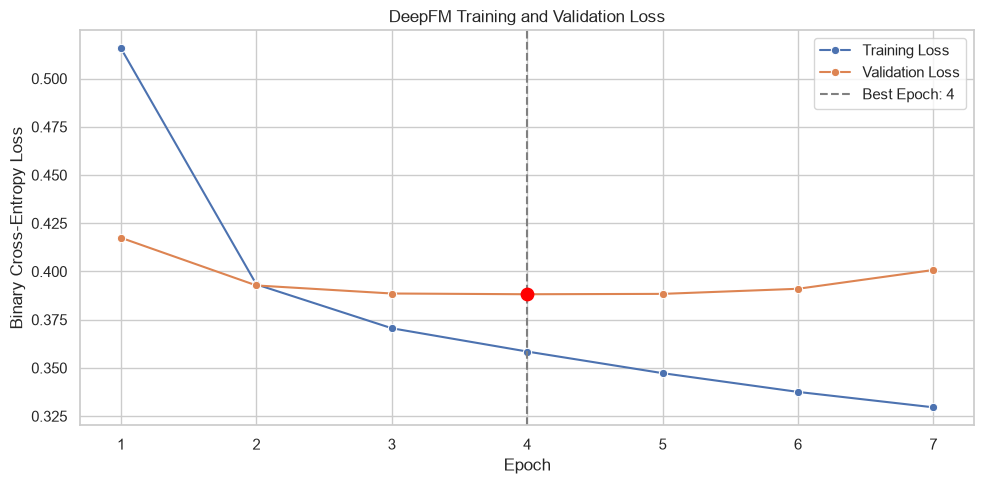

In [16]:
plotTrainingAndValidationLoss(deepFMData, 'DeepFM')

In [17]:
# Mengaktifkan mode evaluasi.
deepFM.eval()

# Menginisialisasi akumulasi test loss serta penyimpanan hasil prediksi dan target.
testLoss = 0.0
testPredictions = []
testTargets = []

# Menggunakan Binary Cross-Entropy Loss untuk klasifikasi biner berbasis logit.
criterion = nn.BCEWithLogitsLoss()

# Melakukan evaluasi pada dataset testing tanpa menghitung gradien.
with torch.inference_mode():
  for batch in testLoader:
    # Memindahkan seluruh tensor batch ke perangkat komputasi.
    userBatch, itemBatch, y = (
      tensor.to(device, non_blocking=True)
      for tensor in batch
    )
    
    # Mengonversi pasangan ID pengguna dan film menjadi matriks fitur DeepFM.
    x = encodeDeepFM(
      userBatch, itemBatch,
      numUsers, numItems,
    )

    # Menghitung prediksi logit dan test loss.
    logits = deepFM(x)
    loss = criterion(logits, y)

    # Mengakumulasi loss berdasarkan jumlah sampel dalam batch.
    testLoss += loss.item() * userBatch.size(0)

    # Mengonversi logit menjadi probabilitas menggunakan sigmoid.
    probabilities = torch.sigmoid(logits)

    # Menyimpan probabilitas prediksi dan target aktual ke dalam list.
    testPredictions.extend(probabilities.cpu().tolist())
    testTargets.extend(y.cpu().tolist())
    
# Menghitung rata-rata test loss berdasarkan jumlah seluruh sampel.
testLoss /= len(testLoader.dataset)

# Menampilkan hasil test loss model.
print(f'Test Loss: {testLoss:.4f}')

Test Loss: 0.3916


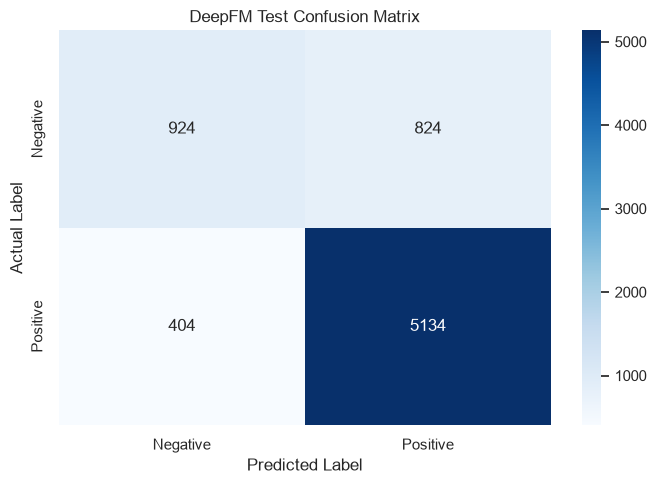

In [18]:
plotConfusionMatrix(testTargets, testPredictions, 'DeepFM')